# 02 - Baseline: DummyClassifier

Before training any neural network we need a reference point: the score that a model gets **without
looking at the text at all**. scikit-learn's `DummyClassifier` ignores the features and predicts only from
the label distribution seen in training, so any useful model has to beat it clearly.

Three strategies are evaluated:

| Strategy | What it predicts |
|---|---|
| `most_frequent` | always the most frequent class of the training labels |
| `stratified` | a random label drawn with the class proportions of the training set |
| `uniform` | a random label with the same probability for every class |

Metrics are computed on train and test with `src/evaluate.py` (positive class = 1 for precision, recall
and F1, plus macro F1 and Cohen's kappa) and saved to `outputs/metrics/dummy.csv`. Figures are saved
to `outputs/figures/` with the prefix `baseline_`.

In [1]:
import sys
import time
from pathlib import Path

sys.path.append("..")

import numpy as np
import pandas as pd
from scipy.stats import binom
from sklearn.dummy import DummyClassifier

from src import evaluate as ev
from src import preprocessing as pp
from src import visualize as viz

pd.set_option("display.width", 160)

SEED = pp.SEED
SEEDS = [42, 43, 44, 45, 46]  # extra seeds for the random strategies
STRATEGIES = ["most_frequent", "stratified", "uniform"]
METRICS_PATH = ev.METRICS_DIR / "dummy.csv"
print("SEED =", SEED, "| seeds for random strategies =", SEEDS)

SEED = 42 | seeds for random strategies = [42, 43, 44, 45, 46]


## 1. Data

The same train/test split used by every model (`data/processed/train.csv` and `test.csv`, 800 / 200
comments). `load_splits` returns the cleaned text, but the dummy classifier never reads it: `X` is only
passed so that `fit` and `predict` know how many samples there are.

In [2]:
X_train, y_train, X_test, y_test = pp.load_splits()

counts = pd.DataFrame({
    "train": pd.Series(y_train).value_counts().sort_index(),
    "test": pd.Series(y_test).value_counts().sort_index(),
})
counts.index = [f"{label} ({name})" for name, label in pp.LABELS.items()]
counts

,train,test
0 (negative),400,100
1 (positive),400,100


## 2. Training and evaluation

`run_dummy` fits one classifier, times the fit and returns one metrics row per split with
`evaluate.metrics_row` (`model = "dummy_<strategy>"`, `n_params = 0` because nothing is learned except the
class prior). `most_frequent` is deterministic, so it is run once with `SEED`; `stratified` and `uniform`
depend on the random state, so they are run with the 5 seeds 42-46 to see how much a random guess moves.

In [3]:
def run_dummy(strategy: str, seed: int) -> tuple[DummyClassifier, list[dict]]:
    """Fit a DummyClassifier and return it with its train and test metric rows."""
    model = DummyClassifier(strategy=strategy, random_state=seed)
    start = time.perf_counter()
    model.fit(X_train, y_train)
    train_time = time.perf_counter() - start

    rows = []
    for split, X, y in [("train", X_train, y_train), ("test", X_test, y_test)]:
        y_pred = model.predict(X)
        rows.append(ev.metrics_row(f"dummy_{strategy}", split, seed, y, y_pred,
                                   train_time_s=train_time, n_params=0))
    return model, rows


rows = []
models = {}
for strategy in STRATEGIES:
    seeds = [SEED] if strategy == "most_frequent" else SEEDS
    for seed in seeds:
        models[(strategy, seed)], new_rows = run_dummy(strategy, seed)
        rows.extend(new_rows)

METRICS_PATH.unlink(missing_ok=True)  # start from a clean file on every run
metrics = ev.save_metrics(rows, METRICS_PATH)
print(f"Saved {len(metrics)} rows to {METRICS_PATH.relative_to(ev.ROOT_DIR)}")
metrics.round(3)

Saved 22 rows to outputs\metrics\dummy.csv


,model,split,seed,accuracy,precision,recall,f1,f1_macro,kappa,train_time_s,n_params
0,dummy_most_frequent,train,42,0.500,0.000,0.000,0.000,0.333,0.000,0.0,0
1,dummy_most_frequent,test,42,0.500,0.000,0.000,0.000,0.333,0.000,0.0,0
2,dummy_stratified,train,42,0.475,0.474,0.465,0.470,0.475,-0.050,0.0,0
3,dummy_stratified,test,42,0.500,0.500,0.510,0.505,0.500,0.000,0.0,0
4,dummy_stratified,train,43,0.472,0.472,0.458,0.464,0.472,-0.055,0.0,0
5,dummy_stratified,test,43,0.500,0.500,0.490,0.495,0.500,0.000,0.0,0
6,dummy_stratified,train,44,0.501,0.501,0.488,0.494,0.501,0.002,0.0,0
7,dummy_stratified,test,44,0.560,0.559,0.570,0.564,0.560,0.120,0.0,0
8,dummy_stratified,train,45,0.502,0.502,0.520,0.511,0.502,0.005,0.0,0
9,dummy_stratified,test,45,0.510,0.509,0.550,0.529,0.509,0.020,0.0,0


### 2.1 Results with the fixed seed (`SEED = 42`)

In [4]:
main = metrics[metrics["seed"] == SEED].set_index(["model", "split"])[ev.SCORE_COLUMNS]
main.round(3)

accuracy  precision  recall     f1  f1_macro  kappa
model               split                                                     
dummy_most_frequent train     0.500      0.000   0.000  0.000     0.333   0.00
                    test      0.500      0.000   0.000  0.000     0.333   0.00
dummy_stratified    train     0.475      0.474   0.465  0.470     0.475  -0.05
                    test      0.500      0.500   0.510  0.505     0.500   0.00
dummy_uniform       train     0.515      0.514   0.532  0.523     0.515   0.03
                    test      0.480      0.480   0.480  0.480     0.480  -0.04

## 3. Summary: mean ± standard deviation

`evaluate.summarize` groups the rows by model and split. `most_frequent` has a single run, so its standard
deviation is NaN and only the mean is shown; for the random strategies it is computed over the 5 seeds.

In [5]:
summary = ev.summarize(metrics)


def mean_std_table(summary: pd.DataFrame, split: str) -> pd.DataFrame:
    """Format each metric of one split as 'mean ± std' (only the mean for a single run)."""
    part = summary[summary["split"] == split].set_index("model")
    table = pd.DataFrame(index=part.index)
    table["runs"] = part["n_runs"]
    for metric in ev.SCORE_COLUMNS:
        mean, std = part[f"{metric}_mean"], part[f"{metric}_std"]
        table[metric] = [f"{m:.3f}" if pd.isna(s) else f"{m:.3f} ± {s:.3f}" for m, s in zip(mean, std)]
    return table


print("Test")
display(mean_std_table(summary, "test"))
print("Train")
display(mean_std_table(summary, "train"))

Test


,runs,accuracy,precision,recall,f1,f1_macro,kappa
model,,,,,,,
dummy_most_frequent,1,0.500,0.000,0.000,0.000,0.333,0.000
dummy_stratified,5,0.517 ± 0.025,0.516 ± 0.024,0.540 ± 0.039,0.528 ± 0.028,0.516 ± 0.025,0.034 ± 0.050
dummy_uniform,5,0.494 ± 0.013,0.494 ± 0.013,0.494 ± 0.019,0.494 ± 0.016,0.494 ± 0.013,-0.012 ± 0.027


Train


,runs,accuracy,precision,recall,f1,f1_macro,kappa
model,,,,,,,
dummy_most_frequent,1,0.500,0.000,0.000,0.000,0.333,0.000
dummy_stratified,5,0.498 ± 0.027,0.497 ± 0.026,0.500 ± 0.046,0.498 ± 0.036,0.498 ± 0.027,-0.004 ± 0.054
dummy_uniform,5,0.506 ± 0.019,0.506 ± 0.019,0.513 ± 0.019,0.510 ± 0.019,0.506 ± 0.019,0.013 ± 0.039


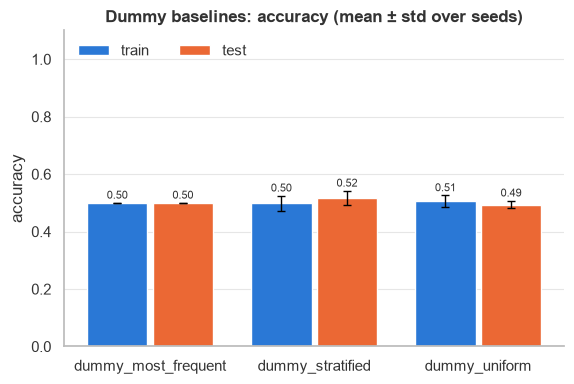

In [6]:
fig = viz.plot_model_comparison(
    metrics, metric="accuracy", order=[f"dummy_{s}" for s in STRATEGIES],
    title="Dummy baselines: accuracy (mean ± std over seeds)", name="baseline_accuracy",
)

## 4. Confusion matrices (test set)

predicted,negative,positive
true,,
negative,100,0
positive,100,0


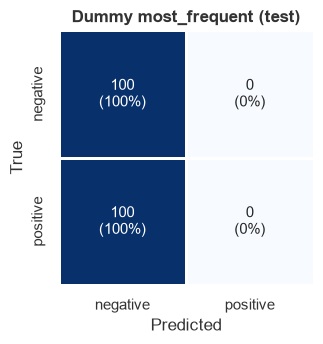

In [7]:
mf_pred = models[("most_frequent", SEED)].predict(X_test)
display(ev.confusion(y_test, mf_pred))
fig = viz.plot_confusion(y_true=y_test, y_pred=mf_pred,
                         title="Dummy most_frequent (test)", name="baseline_confusion_most_frequent")

predicted,negative,positive
true,,
negative,49,51
positive,49,51


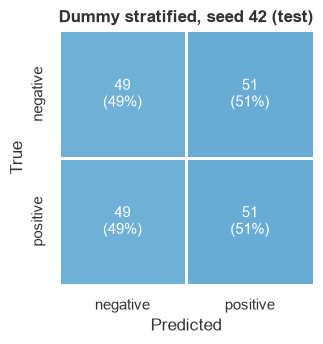

In [8]:
st_pred = models[("stratified", SEED)].predict(X_test)
display(ev.confusion(y_test, st_pred))
fig = viz.plot_confusion(y_true=y_test, y_pred=st_pred,
                         title=f"Dummy stratified, seed {SEED} (test)", name="baseline_confusion_stratified")

## 5. Why the baseline looks like this

**Accuracy ≈ 0.5.** The dataset is balanced (400/400 in train, 100/100 in test). A classifier that does not
read the text can only be right by luck: whatever fraction $q$ of comments it labels positive, it hits
$0.5 \cdot q + 0.5 \cdot (1-q) = 0.5$ of them on average. `most_frequent` gets exactly 0.500 (it is right on
every negative comment and wrong on every positive one), and the random strategies move around 0.5
(test: 0.517 ± 0.025 for `stratified`, 0.494 ± 0.013 for `uniform`). Train and test give the same picture
because nothing is learned from the text, so there is no overfitting to look for.

**Kappa ≈ 0.** Cohen's kappa compares the observed agreement $p_o$ with the agreement expected by chance
$p_e$ from the marginals of the confusion matrix: $\kappa = (p_o - p_e)/(1 - p_e)$. For a classifier whose
predictions are independent of the labels, $p_o \approx p_e$, so $\kappa \approx 0$. For `most_frequent` it is
exactly 0 ($p_o = p_e = 0.5$, computed by hand above). The stratified run with seed 42 also gives exactly 0 on
test: it predicted 51 positives in each true class, so its predictions carry no information about the label.
The small positive and negative values of the other seeds (between -0.055 and 0.12) are only noise.

**Extreme precision and recall of `most_frequent`.** With balanced data both classes have prior 0.5, so the
"most frequent class" is a tie. scikit-learn takes `argmax` of `class_prior_`, which returns the first class
in `classes_ = [0, 1]`; the classifier therefore always predicts **negative (0)** only because 0 comes first,
not because negatives are more common. Since precision, recall and F1 are reported for the positive class:

- recall = 0: none of the 100 positive comments is found;
- precision = 0: there are no positive predictions, so it is 0/0 and `evaluate.py` reports 0
  (`zero_division=0`);
- F1 = 0 and macro F1 = (0.667 + 0) / 2 = 0.333, because the negative class gets F1 = 2·0.5·1/(0.5+1) = 0.667.

If the labels were encoded the other way round it would predict positive for everything and get recall = 1
and precision = 0.5 instead. These extreme values show why accuracy alone is not enough: the same 0.500
accuracy hides a classifier that never detects one of the classes, which F1, macro F1 and kappa expose.

**`stratified` vs `uniform`.** With a 50/50 training prior both strategies draw each label with probability 0.5,
so they are the same random guess; the numbers differ only because each uses the random generator in a
different way.

In [9]:
mf = models[("most_frequent", SEED)]
print("classes_     :", mf.classes_)
print("class_prior_ :", mf.class_prior_)
print("argmax       :", mf.classes_[np.argmax(mf.class_prior_)], "-> always predicts 'negative'")
print("unique predictions on test:", np.unique(mf_pred))

# Cohen's kappa by hand for the most_frequent confusion matrix.
cm = ev.confusion(y_test, mf_pred).to_numpy()
n = cm.sum()
p_o = np.trace(cm) / n
p_e = (cm.sum(axis=1) * cm.sum(axis=0)).sum() / n**2
print(f"p_o = {p_o:.3f}, p_e = {p_e:.3f}, kappa = (p_o - p_e) / (1 - p_e) = {(p_o - p_e) / (1 - p_e):.3f}")

classes_     : [0 1]
class_prior_ : [0.5 0.5]
argmax       : 0 -> always predicts 'negative'
unique predictions on test: [0]
p_o = 0.500, p_e = 0.500, kappa = (p_o - p_e) / (1 - p_e) = 0.000


## 6. How far can a random guess go?

With 200 test comments a random guess does not give exactly 0.5. If the predictions are independent of the
labels, the number of hits follows a Binomial(200, 0.5), so we can compute the accuracy that pure luck
reaches only 5% (and 1%) of the time.

In [10]:
n_test = len(y_test)
for q in (0.95, 0.99):
    print(f"{q:.0%} quantile of chance accuracy on {n_test} comments: {binom.ppf(q, n_test, 0.5) / n_test:.3f}")
print(f"std of chance accuracy: {np.sqrt(0.25 / n_test):.3f}")

95% quantile of chance accuracy on 200 comments: 0.560
99% quantile of chance accuracy on 200 comments: 0.580
std of chance accuracy: 0.035


## 7. Conclusion

- All three dummy strategies stay at chance level on test: accuracy 0.500 (`most_frequent`),
  0.517 ± 0.025 (`stratified`) and 0.494 ± 0.013 (`uniform`), with kappa between -0.012 and 0.034 on
  average. `most_frequent` has precision = recall = F1 = 0 for the positive class and macro F1 = 0.333.
- With 200 test comments, luck alone can reach about **0.56 accuracy** (95% quantile of a Binomial(200, 0.5);
  0.58 at 99%). The best random seed here reached exactly 0.56 (kappa 0.12).

**Threshold for the neural models (Dense, RNN, LSTM) and the Transformer:** to show that they learned
something from the text they must clearly exceed **accuracy and macro F1 of 0.5 and kappa of 0** on the test
set, and in practice stay above the ~0.56-0.58 accuracy that chance can reach on 200 comments, averaged over
seeds. Their rows in `outputs/metrics/` use the same columns as `dummy.csv`, so they can be compared directly.